# Error metrics BEFORE data preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dhruvvvgg/bde-team7/blob/main/notebooks/error_metrics_before.ipynb)

The raw CGWB groundwater table, before any quality control. Run this notebook first; the after notebook cross-checks against the numbers saved here.

Eight error metrics: RMSE, MSE, MAE, MAPE, R², NRMSE, MedAE and Bias (mean error), plus sMAPE.

## The metrics

| Metric | Full form | Formula (e = predicted − actual, y = actual) | Better when | Purpose |
|---|---|---|---|---|
| **RMSE** | Root Mean Square Error | `√( mean(e²) )` | lower | Square root of the average squared error; big misses weigh more. |
| **MSE** | Mean Squared Error | `mean(e²)` | lower | Average squared difference between actual and predicted values. |
| **MAE** | Mean Absolute Error | `mean(|e|)` | lower | Average absolute difference between actual and predicted values. |
| **MAPE** | Mean Absolute Percentage Error | `100 · mean(|e| / |y|), only where |y| ≥ 1 m` | lower | Prediction error as a percentage of the actual value. |
| **R2** | Coefficient of Determination | `1 − Σe² / Σ(y − ȳ)²` | higher | Share of the variation in actual values that the rule explains. |
| **NRMSE** | Normalized Root Mean Square Error | `RMSE / (max y − min y)` | lower | RMSE relative to the scale (range) of the target data. |
| **MedAE** | Median Absolute Error | `median(|e|)` | lower | Median absolute error; insensitive to extreme errors. |
| **Bias** | Mean Error (ME) | `mean(e)` | closer to 0 | Whether predictions systematically over- or under-estimate. |

## How these scores are produced

Data preprocessing does not make predictions, so there is nothing for RMSE, MAE or R² to score directly.
To get *before* and *after* error scores anyway, the **same fixed forecasting rules** are applied to the data
before and after cleaning, and scored on the **2018–2022 test period** (the readings the rules try to predict).
If cleaning makes the data more reliable and regular, the same rule scores better.

Each rule predicts a well's depth to groundwater (metres below ground) for a monitoring round using **only earlier rounds**:

| Rule | Prediction for a round |
|---|---|
| **same season last year** | the reading of the same season one year earlier (e.g. May 2019 → May 2018) |
| **seasonal mean of earlier years** | the mean of all earlier readings of that season, needing at least 5 (the pipeline's seasonal baseline) |
| **previous round** | the immediately previous round (a weak rule that ignores the seasonal cycle) |

These scores measure **data quality, not model skill**; the classifier results belong to the modeling stage.

## Reading notes

- **Units:** RMSE, MAE, MedAE and Bias are in metres of depth to groundwater; MSE is in m²; MAPE is a percentage; R² and NRMSE have no unit.
- **MAPE** divides by the actual value, which explodes for shallow water (0–1 m is common). It is therefore computed only
  where |actual| ≥ 1 m, and the number of readings used is reported (`MAPE_n`). **sMAPE** is a bounded alternative.
- **NRMSE** is RMSE divided by the range of the actual values (max − min); `NRMSE_mean` divides by the mean instead. Because the raw table
  contains impossible values (−97 m to 300 m), its range is huge, which makes its NRMSE look small without the forecasts being better.
- **R²** is measured against each dataset's own spread (variance). Datasets with extreme values have a large spread, so R² can look high
  there. Compare R² only between datasets with the same wells (the like-for-like comparison).
- **Bias** is the mean of (predicted − actual). Positive means the rule predicts water deeper than what was measured. The rules learn from earlier
  years, so a bias appears when the test period differs from them; section 1 reports the measured difference in mean depth.
- The number of scored readings `n` differs between rules (a rule needs its own earlier readings to exist) and between datasets.

## 0. Setup

In [1]:
import os, subprocess, sys, warnings
from pathlib import Path

REPO_URL = "https://github.com/dhruvvvgg/bde-team7.git"      # if the repository is private, put an access token in the URL (never save it in the notebook)

# Use the current folder if it is the repository; otherwise clone it (e.g. in Colab).
if Path("src/gwstress").exists():
    ROOT = Path.cwd()
elif Path("../src/gwstress").exists():          # opened from notebooks/
    ROOT = Path("..").resolve()
else:
    if not Path("bde-team7").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "bde-team7"], check=True)
    ROOT = Path("bde-team7").resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message="DataFrame is highly fragmented")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
from gwstress import error_metrics as em

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 60)
BEFORE, AFTER = "#eb6834", "#2a78d6"            # entity colours: orange = before cleaning, blue = after
INK2, GRID = "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "legend.frameon": False})
SHORT = {"same season last year": "same season\nlast year", "seasonal mean of earlier years": "seasonal mean\nof earlier years",
         "previous round": "previous\nround"}
METRICS = [("RMSE", "m"), ("MSE", "m²"), ("MAE", "m"), ("MAPE", "%"), ("R2", ""), ("NRMSE", "fraction of range"),
           ("MedAE", "m"), ("Bias", "m")]
ROUND_LABELS = [f"{m}-{y % 100:02d}" for y in range(2000, 2023) for m in em.SEASONS]
OUT = ROOT / "reports" / "tables"
OUT.mkdir(parents=True, exist_ok=True)
print("repository:", ROOT)

repository: /home/user/bde-team7


## 1. The data (before cleaning)

In [2]:
ds = em.load_raw_all()
COLOR = BEFORE
display(ds.describe().rename(columns={"value": ds.name}).round(3))

,"raw, all wells"
wells,32299.000
readings,1071989.000
missing % of cells,63.920
min (m),-97.000
max (m),300.000
mean (m),8.036
median (m),5.120
std (m),10.899
negative readings,1359.000
zero readings,13734.000


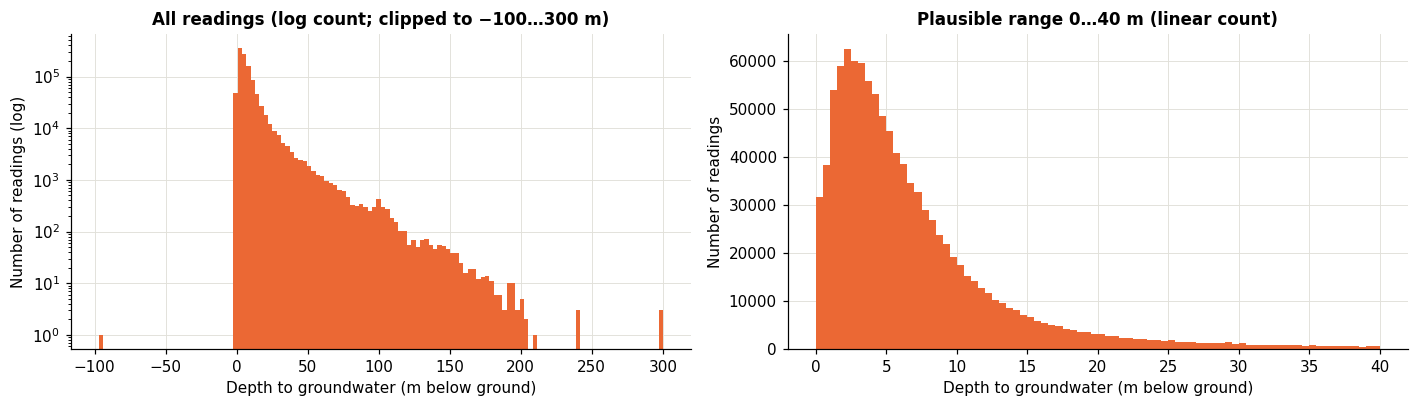

**raw, all wells**: 32,299 wells, 1,071,989 readings; range -97 to 300 m; **1,359 negative** and **2,132 readings above 100 m** (physically implausible).

Mean depth in the earlier years (2000–2017): **7.98 m**; in the test period (2018–2022): **8.19 m** (+0.20 m). Rules that learn from earlier years inherit this shift as bias.

In [3]:
v = ds.values[np.isfinite(ds.values)]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(np.clip(v, -100, 300), bins=130, color=COLOR)
ax[0].set_yscale("log")
ax[0].set_title("All readings (log count; clipped to −100…300 m)")
ax[0].set_xlabel("Depth to groundwater (m below ground)")
ax[0].set_ylabel("Number of readings (log)")
ax[1].hist(v[(v >= 0) & (v <= 40)], bins=80, color=COLOR)
ax[1].set_title("Plausible range 0…40 m (linear count)")
ax[1].set_xlabel("Depth to groundwater (m below ground)")
ax[1].set_ylabel("Number of readings")
plt.tight_layout(); plt.show()
n_bad = int(((v < 0) | (v > 100)).sum())
display(Markdown(f"**{ds.name}**: {len(ds.values):,} wells, {v.size:,} readings; "
                 f"range {v.min():g} to {v.max():g} m; **{int((v < 0).sum()):,} negative** and "
                 f"**{int((v > 100).sum()):,} readings above 100 m** (physically implausible)."))
early = np.nanmean(ds.values[:, :em.TEST_FIRST_COL]); late = np.nanmean(ds.values[:, em.TEST_FIRST_COL:])
display(Markdown(f"Mean depth in the earlier years (2000–2017): **{early:.2f} m**; in the test period (2018–2022): **{late:.2f} m** "
                 f"({late - early:+.2f} m). Rules that learn from earlier years inherit this shift as bias."))

## 2. The forecasting rules in action

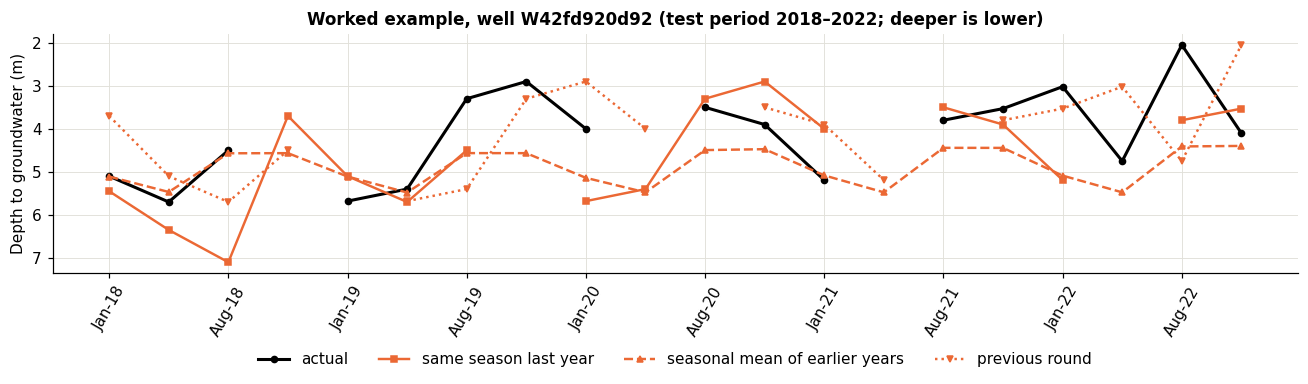

In [4]:
preds = em.predictions(ds.values)
wid = np.flatnonzero(ds.well_ids == "W42fd920d92")
i = int(wid[0]) if len(wid) else int(np.argmax(np.isfinite(ds.values[:, em.TEST_FIRST_COL:]).sum(axis=1)))
cols = np.arange(em.TEST_FIRST_COL, em.N_ROUNDS)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cols, ds.values[i, cols], color="black", lw=2, marker="o", ms=4, label="actual")
for (rule, p), mk, ls in zip(preds.items(), ["s", "^", "v"], ["-", "--", ":"]):
    ax.plot(cols, p[i, cols], color=COLOR, lw=1.6, ls=ls, marker=mk, ms=4, label=rule)
ax.set_xticks(cols[::2], [ROUND_LABELS[c] for c in cols[::2]], rotation=60)
ax.set_ylabel("Depth to groundwater (m)")
ax.invert_yaxis()
ax.set_title(f"Worked example, well {ds.well_ids[i]} (test period 2018–2022; deeper is lower)")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.45))
plt.tight_layout(); plt.show()

## 3. All eight metrics

In [5]:
tbl = em.metric_table(ds)
show = tbl.set_index("rule")[["n", "RMSE", "MSE", "MAE", "MAPE", "R2", "NRMSE", "MedAE", "Bias"]]
show = show.rename(columns={"RMSE": "RMSE (m)", "MSE": "MSE (m²)", "MAE": "MAE (m)", "MAPE": "MAPE (%)",
                            "NRMSE": "NRMSE (range)", "MedAE": "MedAE (m)", "Bias": "Bias / ME (m)"})
display(Markdown(f"### All eight metrics: {ds.name}, test period 2018–2022"))
display(show.round(3))
display(Markdown("Extra scores: NRMSE relative to the mean, sMAPE, and how many readings MAPE could use:"))
display(tbl.set_index("rule")[["NRMSE_mean", "sMAPE", "MAPE_n"]].round(3))

### All eight metrics: raw, all wells, test period 2018–2022

,n,RMSE (m),MSE (m²),MAE (m),MAPE (%),R2,NRMSE (range),MedAE (m),Bias / ME (m)
rule,,,,,,,,,
same season last year,218554,4.555,20.751,1.975,37.823,0.846,0.015,0.920,0.193
seasonal mean of earlier years,214872,5.056,25.562,2.356,42.155,0.784,0.017,1.179,0.214
previous round,192359,4.114,16.923,2.197,46.877,0.851,0.020,1.220,-0.178


Extra scores: NRMSE relative to the mean, sMAPE, and how many readings MAPE could use:

,NRMSE_mean,sMAPE,MAPE_n
rule,,,
same season last year,0.569,34.495,202848
seasonal mean of earlier years,0.668,38.023,198558
previous round,0.528,42.460,182037


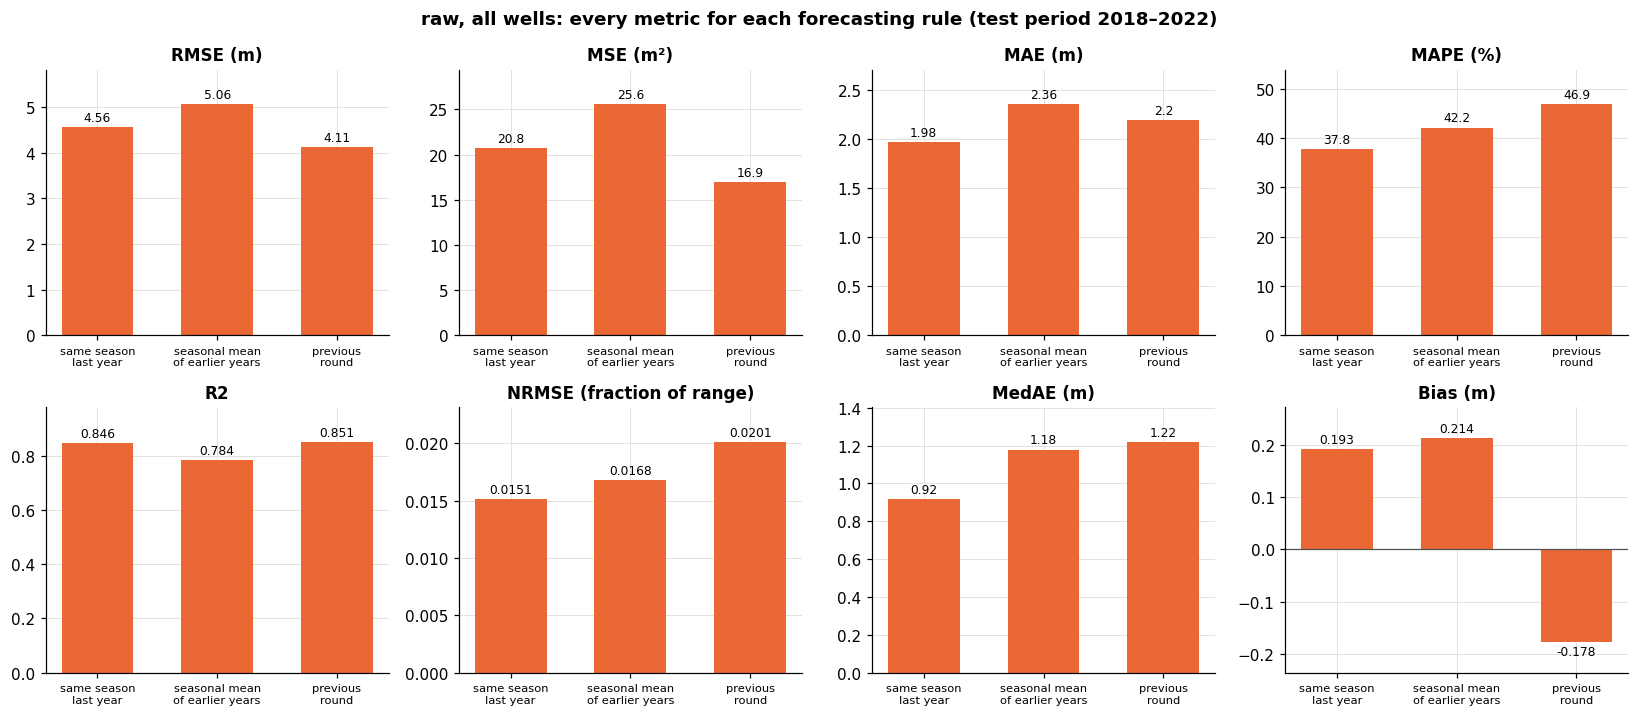

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
for ax, (m, unit) in zip(axes.ravel(), METRICS):
    vals = tbl[m].to_numpy()
    bars = ax.bar(range(3), vals, color=COLOR, width=0.6)
    ax.bar_label(bars, fmt="%.3g", fontsize=8, padding=2)
    ax.set_xticks(range(3), [SHORT[r] for r in tbl.rule], fontsize=7.5)
    ax.set_title(f"{m} ({unit})" if unit else m)
    if m == "Bias":
        ax.axhline(0, color=INK2, lw=0.8)
    ax.margins(y=0.15)
fig.suptitle(f"{ds.name}: every metric for each forecasting rule (test period 2018–2022)", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

## 4. Where the errors are

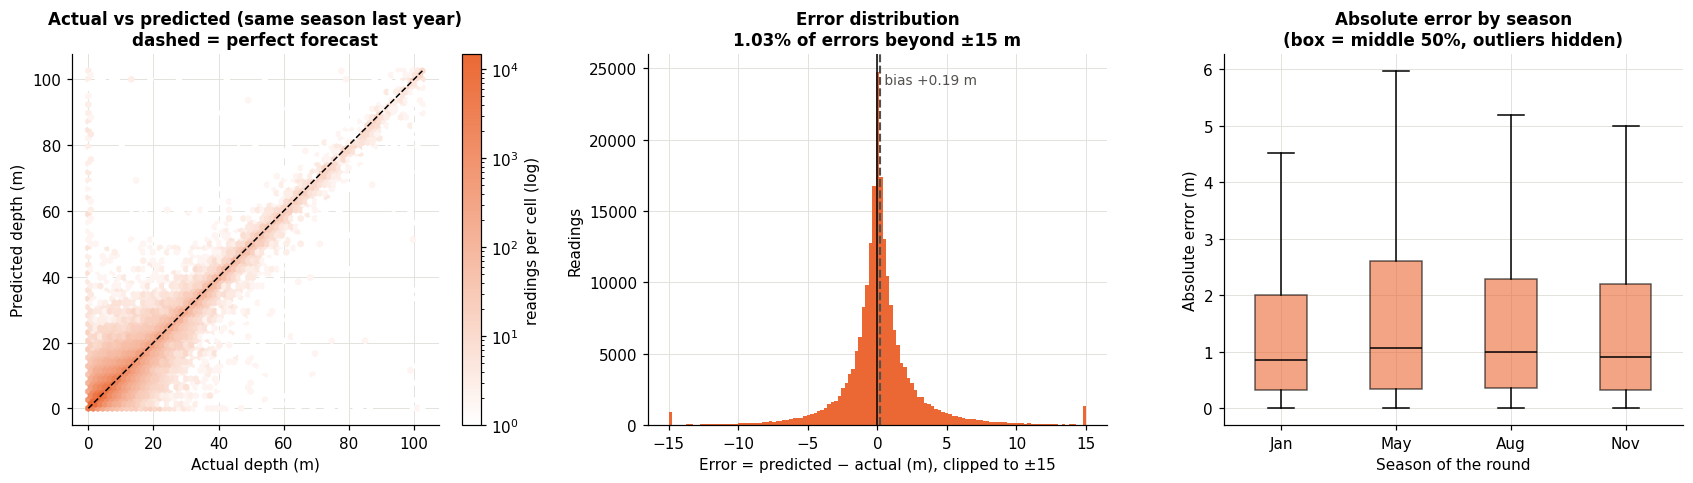

In [7]:
rule = em.PRIMARY_RULE
y, q, pcols, prows = em.test_pairs(ds, rule)
e = q - y
lo, hi = np.percentile(y, [0.2, 99.8])
cmap = LinearSegmentedColormap.from_list("c", ["#ffffff", COLOR])
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.5))
hb = ax[0].hexbin(y, q, gridsize=70, bins="log", cmap=cmap, mincnt=1, extent=(lo, hi, lo, hi))
ax[0].plot([lo, hi], [lo, hi], color="black", lw=1, ls="--")
ax[0].set_xlabel("Actual depth (m)"); ax[0].set_ylabel("Predicted depth (m)")
ax[0].set_title(f"Actual vs predicted ({rule})\ndashed = perfect forecast")
fig.colorbar(hb, ax=ax[0], label="readings per cell (log)")
ax[1].hist(np.clip(e, -15, 15), bins=121, color=COLOR)
ax[1].axvline(0, color="black", lw=1); ax[1].axvline(e.mean(), color=INK2, lw=1.4, ls="--")
ax[1].text(e.mean(), ax[1].get_ylim()[1] * 0.92, f" bias {e.mean():+.2f} m", color=INK2, fontsize=9)
ax[1].set_xlabel("Error = predicted − actual (m), clipped to ±15"); ax[1].set_ylabel("Readings")
ax[1].set_title(f"Error distribution\n{(np.abs(e) > 15).mean() * 100:.2f}% of errors beyond ±15 m")
season = np.array(em.SEASONS)[pcols % 4]
ax[2].boxplot([np.abs(e)[season == s] for s in em.SEASONS], showfliers=False, patch_artist=True,
              boxprops=dict(facecolor=COLOR, alpha=0.6), medianprops=dict(color="black"))
ax[2].set_xticks(range(1, 5), em.SEASONS)
ax[2].set_ylabel("Absolute error (m)"); ax[2].set_xlabel("Season of the round")
ax[2].set_title("Absolute error by season\n(box = middle 50%, outliers hidden)")
plt.tight_layout(); plt.show()

## 5. Breakdown by season, year and state

### By season (same season last year)

,wells,n,RMSE,MSE,MAE,MAPE,R2,NRMSE,MedAE,Bias
season,,,,,,,,,,
Jan,18978,71397,4.162,17.322,1.807,33.030,0.819,0.014,0.85,0.276
May,13573,29024,5.790,33.523,2.421,24.784,0.856,0.032,1.07,-0.153
Aug,17806,54755,3.658,13.379,1.894,47.906,0.876,0.019,0.99,0.235
Nov,19290,63378,5.014,25.136,2.032,41.628,0.824,0.025,0.90,0.221


RMSE (m) by season for every rule:

,same season last year,seasonal mean of earlier years,previous round
season,,,
Jan,4.162,4.117,3.196
May,5.790,7.104,4.789
Aug,3.658,3.826,5.850
Nov,5.014,5.501,3.418


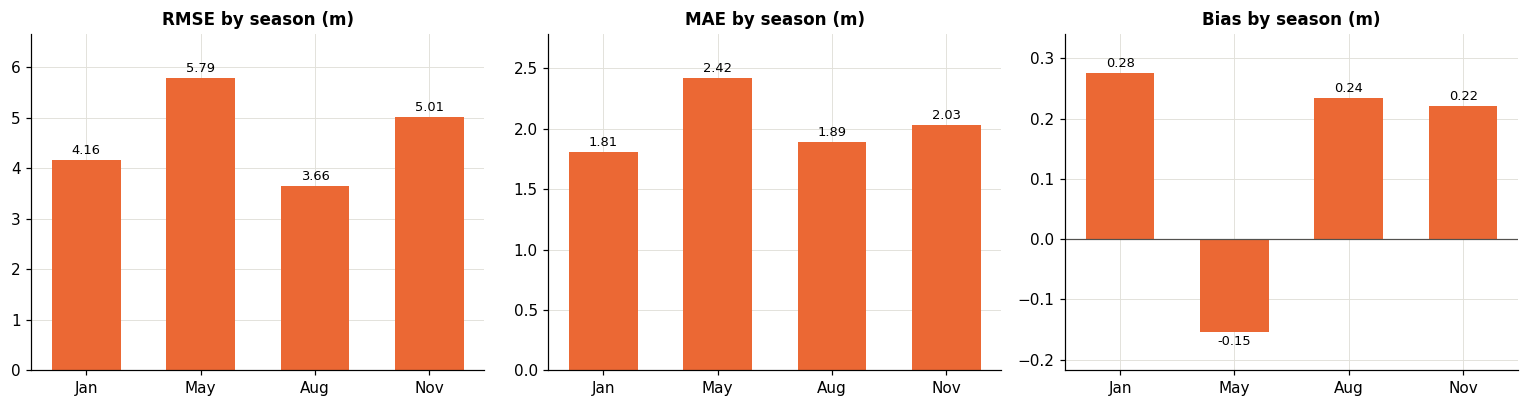

In [8]:
bs = em.breakdown(ds, em.PRIMARY_RULE, "season")
display(Markdown(f"### By season ({em.PRIMARY_RULE})"))
display(bs[["season", "wells", "n", "RMSE", "MSE", "MAE", "MAPE", "R2", "NRMSE", "MedAE", "Bias"]].round(3).set_index("season"))
piv = pd.DataFrame({r: em.breakdown(ds, r, "season").set_index("season")["RMSE"] for r in em.RULES})
display(Markdown("RMSE (m) by season for every rule:"))
display(piv.round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, m in zip(ax, ["RMSE", "MAE", "Bias"]):
    b = a.bar(bs.season.astype(str), bs[m], color=COLOR, width=0.6)
    a.bar_label(b, fmt="%.2f", fontsize=8.5, padding=2)
    a.set_title(f"{m} by season (m)")
    if m == "Bias":
        a.axhline(0, color=INK2, lw=0.8)
    a.margins(y=0.15)
plt.tight_layout(); plt.show()

### By year (same season last year)

,wells,n,RMSE,MAE,R2,MedAE,Bias
year,,,,,,,
2018,19106,51933,4.332,1.951,0.846,0.93,0.060
2019,18565,50739,4.695,2.144,0.827,1.01,-0.079
2020,18091,37350,5.027,2.115,0.837,0.96,0.598
2021,16856,35979,4.466,1.865,0.864,0.85,0.101
2022,17368,42553,4.283,1.776,0.857,0.85,0.401


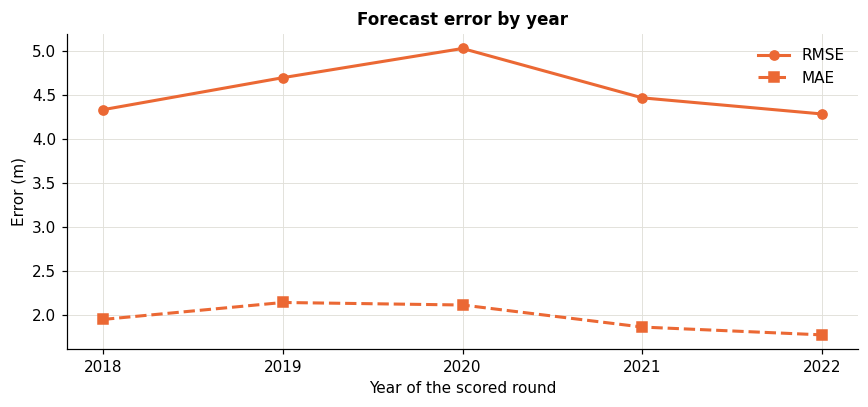

In [9]:
by = em.breakdown(ds, em.PRIMARY_RULE, "year")
display(Markdown(f"### By year ({em.PRIMARY_RULE})"))
display(by[["year", "wells", "n", "RMSE", "MAE", "R2", "MedAE", "Bias"]].round(3).set_index("year"))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(by.year, by.RMSE, color=COLOR, lw=2, marker="o", label="RMSE")
ax.plot(by.year, by.MAE, color=COLOR, lw=2, ls="--", marker="s", label="MAE")
ax.set_xticks(by.year); ax.set_ylabel("Error (m)"); ax.set_xlabel("Year of the scored round")
ax.set_title("Forecast error by year"); ax.legend()
plt.tight_layout(); plt.show()

### By state (same season last year), sorted by RMSE

,wells,n,RMSE,MAE,R2,MedAE,Bias
state,,,,,,,
Haryana,457,3688,8.863,2.091,0.647,0.820,-0.128
Rajasthan,2779,23417,8.061,3.245,0.864,1.360,0.274
Andhra Pradesh,1191,14701,5.820,2.156,0.652,0.850,0.207
Telangana,1235,13047,5.757,3.011,0.531,1.450,0.134
Tamil Nadu,800,7455,5.197,2.723,0.529,1.520,0.863
Gujarat,1128,10920,5.190,2.617,0.947,1.320,0.133
Uttarakhand,60,546,4.590,2.170,0.869,0.935,-0.217
Madhya Pradesh,1539,22950,4.518,2.330,0.503,1.220,0.407
Karnataka,1656,19522,3.789,2.066,0.647,1.070,0.503


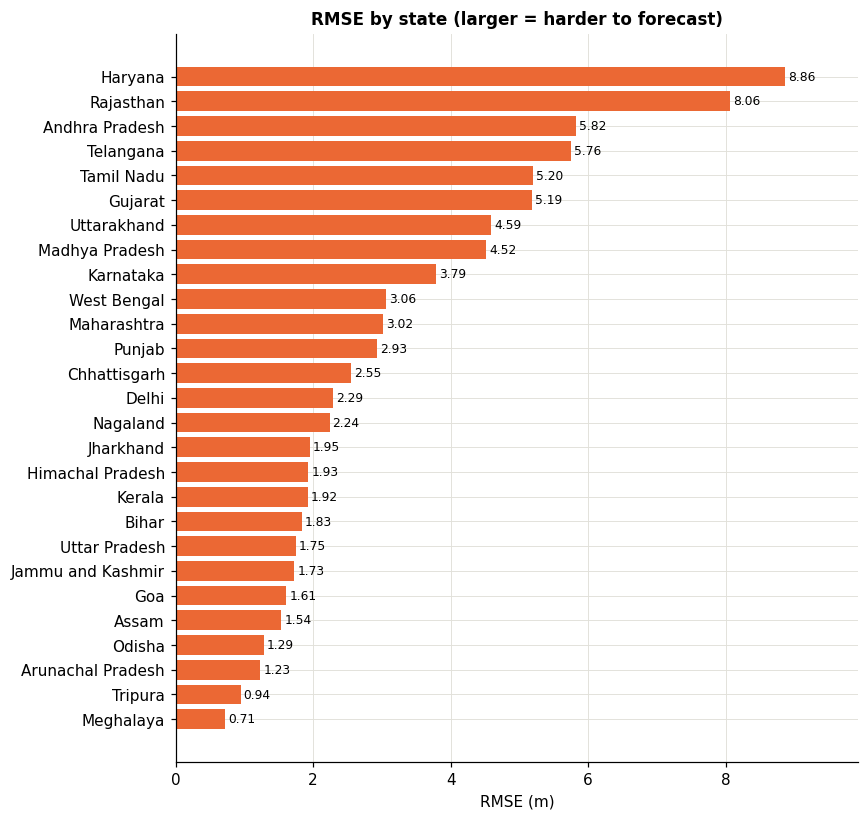

In [10]:
st = em.breakdown(ds, em.PRIMARY_RULE, "state").sort_values("RMSE", ascending=False)
display(Markdown(f"### By state ({em.PRIMARY_RULE}), sorted by RMSE"))
display(st[["state", "wells", "n", "RMSE", "MAE", "R2", "MedAE", "Bias"]].round(3).set_index("state"))
fig, ax = plt.subplots(figsize=(8, max(3.5, 0.28 * len(st))))
b = ax.barh(st.state[::-1], st.RMSE[::-1], color=COLOR)
ax.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
ax.set_xlabel("RMSE (m)"); ax.set_title("RMSE by state (larger = harder to forecast)")
ax.margins(x=0.12)
plt.tight_layout(); plt.show()

## 6. Like-for-like baseline

In [11]:
raw_same = em.load_raw_same_wells()
tbl_same = em.metric_table(raw_same)
show = tbl_same.set_index("rule")[["n", "RMSE", "MSE", "MAE", "MAPE", "R2", "NRMSE", "MedAE", "Bias"]]
display(Markdown("### Like-for-like baseline: the raw values of exactly the 2,759 wells that survive cleaning"))
display(Markdown("This is the fair 'before' for the 'after' notebook: same wells, same rounds; only the values differ."))
display(show.round(3))
display(raw_same.describe().rename(columns={"value": raw_same.name}).round(3))

### Like-for-like baseline: the raw values of exactly the 2,759 wells that survive cleaning

This is the fair 'before' for the 'after' notebook: same wells, same rounds; only the values differ.

,n,RMSE,MSE,MAE,MAPE,R2,NRMSE,MedAE,Bias
rule,,,,,,,,,
same season last year,39110,2.684,7.203,1.542,37.779,0.689,0.040,0.850,0.210
seasonal mean of earlier years,44379,2.535,6.424,1.595,39.739,0.727,0.038,0.989,0.350
previous round,35288,3.209,10.298,2.053,50.850,0.572,0.048,1.260,-0.179


,"raw values, same 2,759 wells"
wells,2759.000
readings,220475.000
missing % of cells,13.140
min (m),0.000
max (m),95.880
mean (m),5.790
median (m),4.610
std (m),4.914
negative readings,0.000
zero readings,11.000


## 7. Save the results

In [12]:
results = pd.concat([tbl, tbl_same], ignore_index=True)
results.to_csv(OUT / "error_metrics_before.csv", index=False)
by_season = pd.concat([em.breakdown(d, r, "season").assign(data=d.name, rule=r)
                       for d in (ds, raw_same) for r in em.RULES], ignore_index=True)
by_season.to_csv(OUT / "error_metrics_before_by_season.csv", index=False)
print("saved:", OUT / "error_metrics_before.csv")
print("saved:", OUT / "error_metrics_before_by_season.csv")

saved: /home/user/bde-team7/reports/tables/error_metrics_before.csv
saved: /home/user/bde-team7/reports/tables/error_metrics_before_by_season.csv


In [13]:
p = tbl.set_index("rule").loc[em.PRIMARY_RULE]
s = tbl_same.set_index("rule").loc[em.PRIMARY_RULE]
display(Markdown(f'''
### Before-cleaning summary (rule: {em.PRIMARY_RULE}, test period 2018–2022)

- **Whole raw table:** RMSE **{p.RMSE:.2f} m**, MAE **{p.MAE:.2f} m**, R² **{p.R2:.3f}**, MedAE {p.MedAE:.2f} m, bias {p.Bias:+.2f} m, on {int(p.n):,} readings.
- **Raw values of the same 2,759 wells:** RMSE **{s.RMSE:.2f} m**, MAE **{s.MAE:.2f} m**, R² **{s.R2:.3f}**, on {int(s.n):,} readings.
- RMSE / MAE is **{p.RMSE / p.MAE:.2f}** for the whole raw table and **{s.RMSE / s.MAE:.2f}** for the same-wells raw values. A larger ratio means
  heavier-tailed errors: a few very large misses dominate the squared-error metrics (RMSE, MSE) more than the absolute ones (MAE, MedAE).
- Next: **error_metrics_after.ipynb** repeats this on the cleaned data and compares.
'''))


### Before-cleaning summary (rule: same season last year, test period 2018–2022)

- **Whole raw table:** RMSE **4.56 m**, MAE **1.98 m**, R² **0.846**, MedAE 0.92 m, bias +0.19 m, on 218,554 readings.
- **Raw values of the same 2,759 wells:** RMSE **2.68 m**, MAE **1.54 m**, R² **0.689**, on 39,110 readings.
- RMSE / MAE is **2.31** for the whole raw table and **1.74** for the same-wells raw values. A larger ratio means
  heavier-tailed errors: a few very large misses dominate the squared-error metrics (RMSE, MSE) more than the absolute ones (MAE, MedAE).
- Next: **error_metrics_after.ipynb** repeats this on the cleaned data and compares.
